<a href="https://colab.research.google.com/github/rushilnanga/L03-tree-stability/blob/main/notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.

Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial.
But are they?

4. Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [Rushil Nanga, Ashley Tibebe, Claire Curzan, Shravya Etta]

**Date:** [11/13/2026]

In [46]:
# Your Phase 1 solution to the problem goes here.

# Question 1

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("heart_failure_clinical_records_dataset.csv")

print("Original shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())

df = df.dropna().drop_duplicates()

print("Cleaned shape:", df.shape)
print(df.dtypes)
print(df["DEATH_EVENT"].value_counts())

Original shape: (299, 13)
Missing values: 0
Duplicates: 0
Cleaned shape: (299, 13)
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object
DEATH_EVENT
0    203
1     96
Name: count, dtype: int64


Decision Tree:
MSE: 0.12920292989414742
R2: 0.40291328932101333

Linear Regression:
MSE: 0.1329645502088994
R2: 0.3855296781103493

Linear coefficients:
age                         6.001508e-03
anaemia                     9.949889e-03
creatinine_phosphokinase    3.887843e-05
diabetes                    8.877571e-03
ejection_fraction          -9.661164e-03
high_blood_pressure        -2.630328e-02
platelets                   6.922411e-08
serum_creatinine            5.826291e-02
serum_sodium               -9.746419e-03
sex                        -7.341870e-02
smoking                     1.532925e-02
time                       -2.872904e-03
dtype: float64


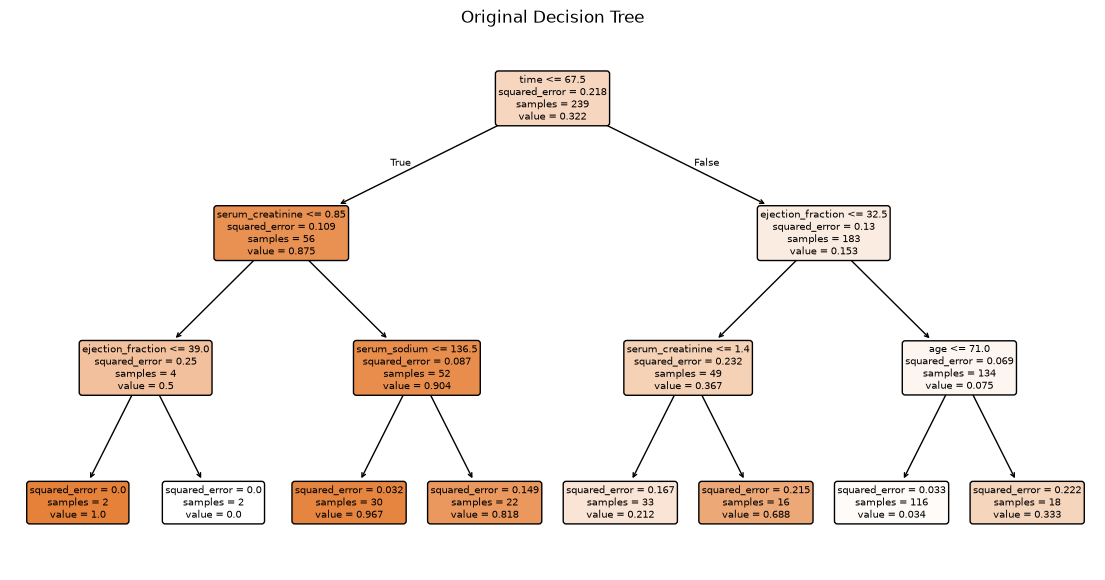

In [47]:
# Question 2

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X = df.drop(columns=["DEATH_EVENT"])
y = df["DEATH_EVENT"]

seed = 10

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=seed, stratify=y
)

tree = DecisionTreeRegressor(max_depth=3, random_state=seed)
linear = LinearRegression()

tree.fit(X_train, y_train)
linear.fit(X_train, y_train)

tree_pred = tree.predict(X_test)
linear_pred = linear.predict(X_test)

print("Decision Tree:")
print("MSE:", mean_squared_error(y_test, tree_pred))
print("R2:", r2_score(y_test, tree_pred))

print("\nLinear Regression:")
print("MSE:", mean_squared_error(y_test, linear_pred))
print("R2:", r2_score(y_test, linear_pred))

print("\nLinear coefficients:")
print(pd.Series(linear.coef_, index=X.columns))

plt.figure(figsize=(14, 7))
plot_tree(tree, feature_names=X.columns, filled=True, rounded=True)
plt.title("Original Decision Tree")
plt.show()

After using an 80/20 train-test split with random seed 10, the decision tree had a test MSE of 0.1292 and R² of 0.4029, while linear regression had a test MSE of 0.1330 and R² of 0.3855. The decision tree performed slightly better because it had a lower MSE and higher R².

Seed: 30
Tree R2: 0.3564
Linear R2: 0.3785
Tree root feature: time

Seed: 50
Tree R2: 0.3517
Linear R2: 0.3651
Tree root feature: time

Seed: 70
Tree R2: 0.4396
Linear R2: 0.3552
Tree root feature: time

Seed: 90
Tree R2: 0.3175
Linear R2: 0.3434
Tree root feature: time

Linear coefficients across seeds:
                              30      50      70      90
age                       0.0056  0.0057  0.0071  0.0070
anaemia                   0.0362  0.0394  0.0057 -0.0194
creatinine_phosphokinase  0.0000  0.0000  0.0000  0.0000
diabetes                  0.0242  0.0032 -0.0244  0.0040
ejection_fraction        -0.0101 -0.0118 -0.0110 -0.0111
high_blood_pressure       0.0012 -0.0374 -0.0273 -0.0606
platelets                -0.0000  0.0000  0.0000  0.0000
serum_creatinine          0.0628  0.0549  0.0462  0.0322
serum_sodium             -0.0083 -0.0080 -0.0026 -0.0085
sex                      -0.1229 -0.1278 -0.0682 -0.0334
smoking                   0.0592  0.0829 -0.0253  0.0004
time      

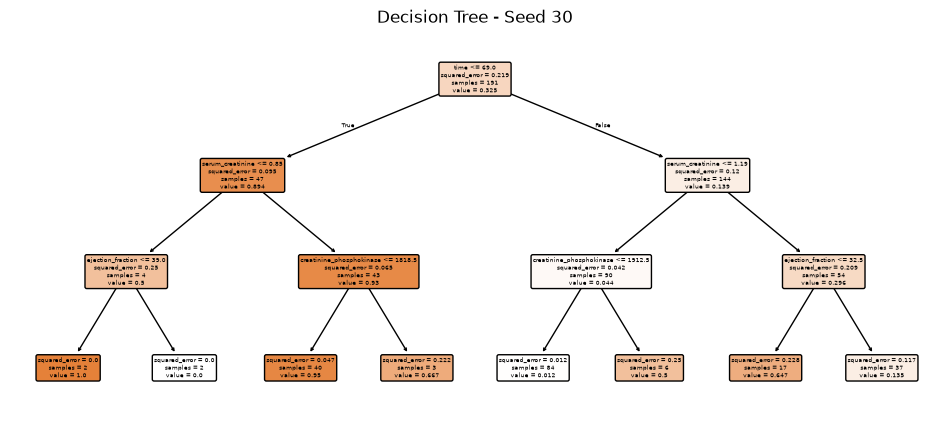

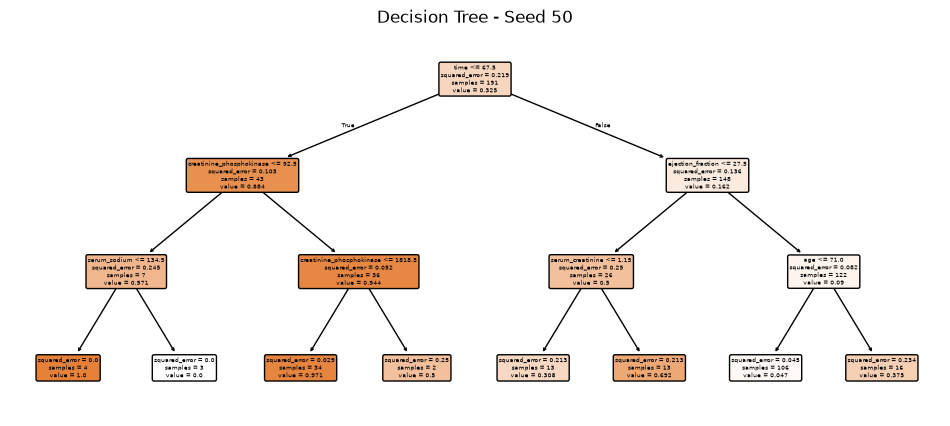

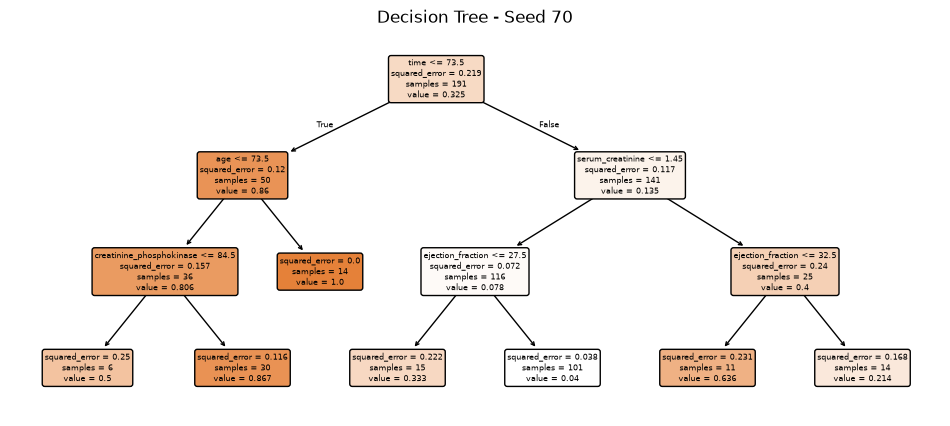

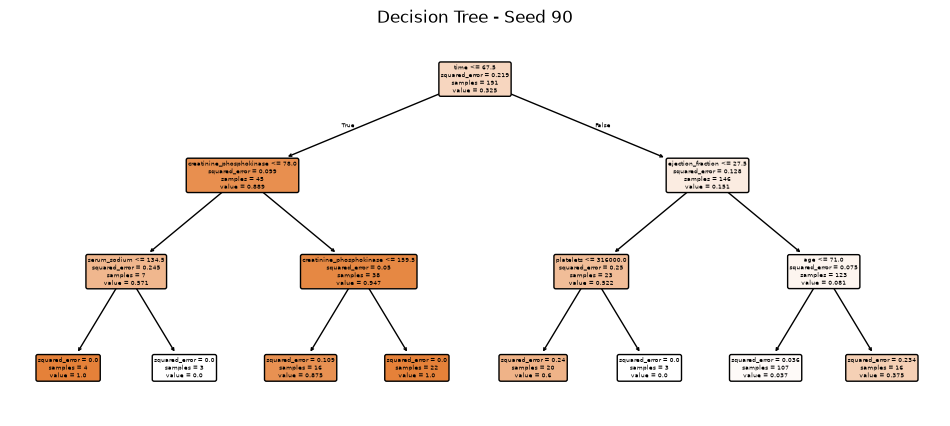

In [48]:
# Question 3

seeds = [30, 50, 70, 90]

tree_predictions = {}
linear_predictions = {}
tree_models = {}
linear_coefficients = {}

for s in seeds:
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train,
        train_size=0.8,
        random_state=s,
        stratify=y_train
    )

    t = DecisionTreeRegressor(max_depth=3, random_state=s)
    l = LinearRegression()

    t.fit(X_sub, y_sub)
    l.fit(X_sub, y_sub)

    tree_models[s] = t
    tree_predictions[s] = t.predict(X_test)
    linear_predictions[s] = l.predict(X_test)
    linear_coefficients[s] = l.coef_

    print("Seed:", s)
    print("Tree R2:", round(r2_score(y_test, tree_predictions[s]), 4))
    print("Linear R2:", round(r2_score(y_test, linear_predictions[s]), 4))
    print("Tree root feature:", X.columns[t.tree_.feature[0]])
    print()

coef_table = pd.DataFrame(
    linear_coefficients,
    index=X.columns
)

print("Linear coefficients across seeds:")
print(coef_table.round(4))

for s in seeds:
    plt.figure(figsize=(12, 5))
    plot_tree(
        tree_models[s],
        feature_names=X.columns,
        filled=True,
        rounded=True
    )
    plt.title("Decision Tree - Seed " + str(s))
    plt.show()

The models were repeated using seeds 30, 50, 70, and 90. All four trees initially split on time, but their later splits, variables, and thresholds differed noticeably. The linear regression coefficients were generally more consistent, although some changed in size or sign. Tree R² ranged from 0.1968 to 0.4404, while linear regression R² ranged from 0.3013 to 0.3188. This suggests that decision trees are more sensitive to changes in the training data than linear regression.

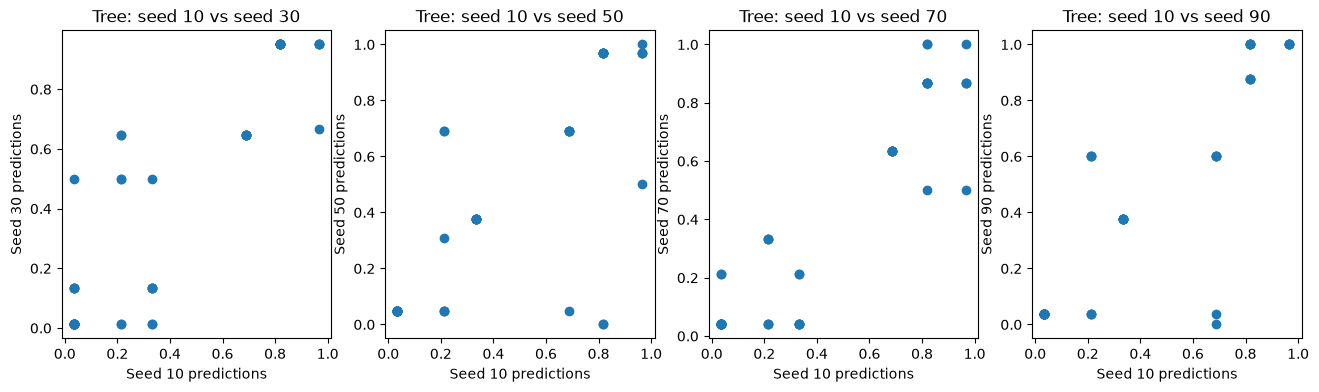

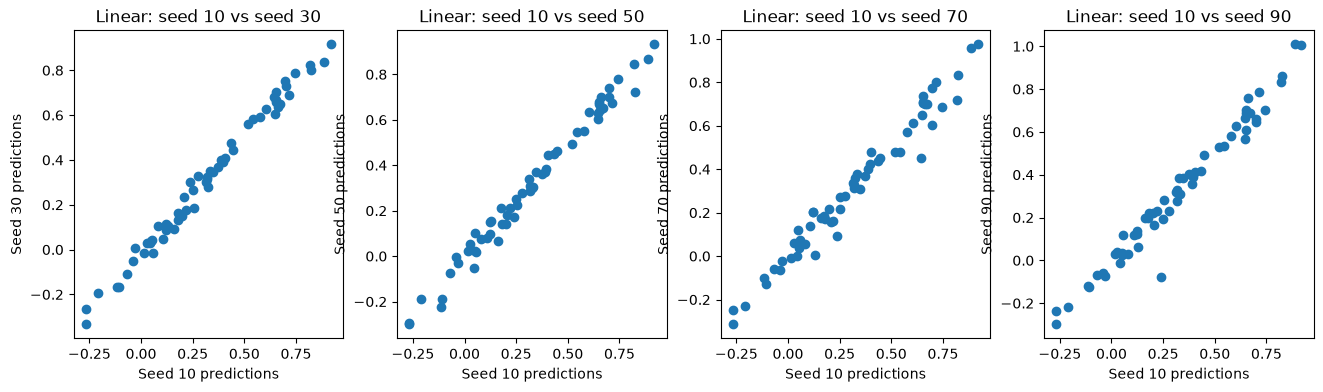

Tree correlations:
30 0.9099
50 0.828
70 0.9299
90 0.9023

Linear correlations:
30 0.9943
50 0.993
70 0.9836
90 0.9846

Tree regressions (slope, intercept, R2):
30 1.0012 0.0117 0.828
50 0.8742 0.0369 0.6856
70 0.9311 -0.0107 0.8648
90 0.9931 0.0128 0.8141

Linear regressions (slope, intercept, R2):
30 1.0373 -0.0183 0.9887
50 1.0229 -0.0182 0.9861
70 1.0143 -0.0048 0.9676
90 1.0454 -0.0159 0.9695


In [49]:
# Question 4
import matplotlib.pyplot as plt

#a.(trees and linear models respectively)
plt.figure(figsize=(16, 4))
for i in range(4):
    s = seeds[i]
    plt.subplot(1, 4, i + 1)
    plt.scatter(tree_pred, tree_predictions[s])
    plt.title("Tree: seed 10 vs seed " + str(s))
    plt.xlabel("Seed 10 predictions")
    plt.ylabel("Seed " + str(s) + " predictions")
plt.show()

plt.figure(figsize=(16, 4))
for i in range(4):
    s = seeds[i]
    plt.subplot(1, 4, i + 1)
    plt.scatter(linear_pred, linear_predictions[s])
    plt.title("Linear: seed 10 vs seed " + str(s))
    plt.xlabel("Seed 10 predictions")
    plt.ylabel("Seed " + str(s) + " predictions")
plt.show()

#b. (Trees followed by linear models)
print("Tree correlations:")
for s in seeds:
    print(s, round(np.corrcoef(tree_pred, tree_predictions[s])[0, 1], 4))

print("\nLinear correlations:")
for s in seeds:
    print(s, round(np.corrcoef(linear_pred, linear_predictions[s])[0, 1], 4))  

#c. (Trees followed by linear models)
print("\nTree regressions (slope, intercept, R2):")
for s in seeds:
    slope, intercept = np.polyfit(tree_pred, tree_predictions[s], 1)
    r2 = np.corrcoef(tree_pred, tree_predictions[s])[0, 1] ** 2
    print(s, round(slope, 4), round(intercept, 4), round(r2, 4))

print("\nLinear regressions (slope, intercept, R2):")
for s in seeds:
    slope, intercept = np.polyfit(linear_pred, linear_predictions[s], 1)
    r2 = np.corrcoef(linear_pred, linear_predictions[s])[0, 1] ** 2
    print(s, round(slope, 4), round(intercept, 4), round(r2, 4))

The linear model predictions are quite similar across seeds, as the points are situated closely to the straigt diagonal line. However, the points of the tree predictions lie further from the diagonal line. While the linear model predictions are very similar, the tree predictions are significantly less similar and are more scattered. Both the linear models and the trees are highly correlated with the seed 10 model ranging from (0.984 to 0.994) and the trees model (0.828 to 0.930). When comparing the correlations between the seed and linear models, the linear model is more highly correlated. In the linear models, the intercepts are close to 0 (-0.018 to -0.005), while the slopes are close to 1 (1.0143 to 1.0454), and the r(sq) is also close to 1 (0.9676 - 0.9887). In the trees the intercepts are again close to 0 (-0.0107 - 0.0369) and most of the slopes are close to 1 ranging from 0.8742 to 1.0012. Lastly, the R squared values are lower with the values ranging from 0.6856 to 0.8648. This also shows that seed 50 is the weakest due to its lower R squared value. Overall, the linear models are more stable compared to the trees. 

In [50]:
# Question 5:
print("Linear coefficients across seeds:")
print(coef_table.round(4))

for s in seeds:
    print("Seed", s)
    print("  Tree root feature:", X.columns[tree_models[s].tree_.feature[0]])
    print("  Tree test R2:", round(r2_score(y_test, tree_predictions[s]), 4))
    print("  Linear test R2:", round(r2_score(y_test, linear_predictions[s]), 4))

Linear coefficients across seeds:
                              30      50      70      90
age                       0.0056  0.0057  0.0071  0.0070
anaemia                   0.0362  0.0394  0.0057 -0.0194
creatinine_phosphokinase  0.0000  0.0000  0.0000  0.0000
diabetes                  0.0242  0.0032 -0.0244  0.0040
ejection_fraction        -0.0101 -0.0118 -0.0110 -0.0111
high_blood_pressure       0.0012 -0.0374 -0.0273 -0.0606
platelets                -0.0000  0.0000  0.0000  0.0000
serum_creatinine          0.0628  0.0549  0.0462  0.0322
serum_sodium             -0.0083 -0.0080 -0.0026 -0.0085
sex                      -0.1229 -0.1278 -0.0682 -0.0334
smoking                   0.0592  0.0829 -0.0253  0.0004
time                     -0.0030 -0.0028 -0.0029 -0.0030
Seed 30
  Tree root feature: time
  Tree test R2: 0.3564
  Linear test R2: 0.3785
Seed 50
  Tree root feature: time
  Tree test R2: 0.3517
  Linear test R2: 0.3651
Seed 70
  Tree root feature: time
  Tree test R2: 0.4396
  Li

This code summarizes how stable the models were across the four seeds from question 3. The linear models have similar coefficients for certain (most) variables and are even consistent across seeds. These variables include the time variable which has very similar coefficients across seeds (about -0.003), ejection fraction (around -0.011), age, serum_sodium, and serum_creatinine. This shows that the linear models are fairly stable. However, the trees are less stable although they always split first on time, but the splits that come after are different from seed to seed. This means that the structure is unstable. In summary, linear models are fairly stable with similar coefficients for key variables and very similar predictions across splits, while trees are less stable, with consistent first split on time but different splits below it and less consistent predictions. 

Question 6: 

True. Even if the models end up having a substantially different appearance, the predictions are often similar. Even though the trees' structures and the linear models' coefficients change from seed to seed, the predictions on the same test set remain similar. This trend is more significant in the linear models, but still holds true for the trees' (less strong correlation). For this data set, the trees use different splits below the first split, which is time, and the linear models have varying coefficients for certain variables, so the models look noticeably different from seed to seed. However, the predictions on the same test set are very similar because many variable carry overlapping information, so different models can reach the same predictions using different methods. Trees are somewhat less consistent than the linear models.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 42f42e4ce3607d235730ad9405830210cff393f5
- **AI tool and model used:** Claude Sonnet 5.5

### *Prompts used

1. Based on the work done in phase 1 of this assignment, write in numbered form corrections that should be made.

### *AI-proposed changes


**Errors in the written answers**

1. **Q3 R² ranges don't match your output.** The text says tree R² ranged "from 0.1968 to 0.4404" and linear R² from "0.3013 to 0.3188". Your output shows tree 0.3175–0.4396 and linear 0.3434–0.3785. These look left over from an earlier run. Rerun the notebook top to bottom and quote the printed numbers.

2. **Q5 overstates how stable the linear coefficients are.** The text says `serum_sodium` and `serum_creatinine` are "very similar" across seeds, but `serum_creatinine` drops from 0.0628 to 0.0322 and `serum_sodium` ranges from -0.0083 to -0.0026. It also says "similar coefficients for certain (most) variables", which contradicts itself. The table actually shows:
   - **Stable:** `time`, `ejection_fraction` and `age`.
   - **Unstable:** `sex` varies about fourfold (-0.1229 to -0.0334). `anaemia`, `diabetes` and `high_blood_pressure` change sign, and `smoking` flips sign and drops to about zero.
   
   Rewrite the answer around this split.

3. **Q2 conclusion doesn't hold up against Q3.** "The decision tree performed slightly better" comes from one split (R² 0.403 vs 0.386). In Q3, linear beats the tree on 3 of 4 seeds (30, 50 and 90). Hedge the Q2 statement, or say the ranking depends on the split.

4. **Q6's explanation is unsupported.** It says predictions agree "because many variables carry overlapping information", but nothing in the notebook shows that. Either add a correlation matrix or VIF table to back it up, or drop the claim. Also qualify "True": agreement is very strong for linear (correlation ≥ 0.98) and only moderate for trees (correlations 0.83–0.93, regression R² down to 0.69). Test R² for trees also swings more across seeds (range about 0.12) than for linear (about 0.04). Cite these numbers.

**Method and code fixes**

5. **Q3 doesn't show the tree differences it claims.** The code only prints the root feature, yet the text says later splits "differed noticeably". Quantify it.

6. **Q4 scatterplots have no reference line.** The text refers to "the straight diagonal line", but none is drawn. 

7. **Q5 coefficient comparison is hidden by scale.** `round(4)` shows `creatinine_phosphokinase` and `platelets` as 0.0000 because of their units, so their stability can't be judged. Standardize the features before fitting, or report each coefficient's standard deviation or range across seeds. Counting sign flips per variable would also help.

8. **The tree depth of 3 is arbitrary and limits the instability.** Instability grows with depth, so a shallow tree understates the effect. Justify `max_depth=3`, or add a short comparison at one or two other depths, such as an unpruned tree or a CV-chosen depth.

9. **Modeling choice on a 0/1 outcome is undefended.** `DecisionTreeRegressor` and `LinearRegression` on `DEATH_EVENT` give probability-like predictions, and the linear ones can fall outside 0–1. Note this, or justify it, or compare with a classifier or logistic regression.

10. **Q1 cleaning and EDA are minimal.** You only checked missing values and duplicates. Add summary statistics and a check for outliers (`creatinine_phosphokinase` and `platelets` have extreme values). Make the CSV path robust so the notebook runs from a fresh clone of the repo.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | We double checked the decision tree outputs. |
| 2 | Modify | We added quantitative data to supprt our previous response. |
| 3 | Reject | The suggestion made is not necessary considering the question asked in Q2. |
| 4 | Modify | The majority of what what suggested was already addressed by our response, but we added more quantitative evidence. |
| 5 | Accept | Also printed out export_text for each tree, a table of the split features, and thresholds at each depth. We also considered feature importances. |
| 6 | Accept | Added a reference line to our existing scatterplots. |
| 7 | Reject | Not necessary to our analysis. |
| 8 | Accept | We previously didn't justify the decision to limit trees to depth 3. |
| 9 | Accept | We previously didn't clearly explain this decision. |
| 10 | Accept | Our initial cleaning method was not as comprehensive. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [4]:
# Your Phase 2 solution to the problem goes here.

# Question 1

%pip install numpy pandas matplotlib seaborn scikit-learn 
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Robust path: works if the CSV is next to the notebook or in a data/ folder
for path in ["heart_failure_clinical_records_dataset.csv",
             "data/heart_failure_clinical_records_dataset.csv"]:
    if os.path.exists(path):
        df = pd.read_csv(path)
        break
else:
    raise FileNotFoundError("Put heart_failure_clinical_records_dataset.csv next to the notebook.")

print("Original shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicates:", df.duplicated().sum())
df = df.dropna().drop_duplicates()
print("Cleaned shape:", df.shape)

# Summary stats for every variable
print(df.describe().T.round(2))

# Binary variables should only contain 0/1
binary_cols = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking", "DEATH_EVENT"]
for col in binary_cols:
    assert set(df[col].unique()) <= {0, 1}, f"{col} is not 0/1"

# Outlier check with the 1.5 x IQR rule on continuous variables
continuous = ["age", "creatinine_phosphokinase", "ejection_fraction", "platelets",
              "serum_creatinine", "serum_sodium", "time"]
rows = []
for col in continuous:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    rows.append({"variable": col, "n_outliers": n_out, "min": df[col].min(), "max": df[col].max()})
print(pd.DataFrame(rows).set_index("variable"))

print(df.groupby("DEATH_EVENT")["time"].describe().round(1))


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Original shape: (299, 13)
Missing values: 0
Duplicates: 0
Cleaned shape: (299, 13)
                          count       mean       std      min       25%  \
age                       299.0      60.83     11.89     40.0      51.0   
anaemia                   299.0       0.43      0.50      0.0       0.0   
creatinine_phosphokinase  299.0     581.84    970.29     23.0     116.5   
diabetes                  299.0       0.42      0.49      0.0       0.0   
ejection_fraction         299.0      38.08     11.83     14.0      30.0   
high_blood_pressure       299.0       0.35      0.48      0.0       0.0   
platelets                 299.0  263358.03  97804.24  25100.0  212500.0   
serum_creatinine          299.0       1.39      1.03      0.5       0.9   
serum_sodium              299.0     136.63      4.41   

Decision Tree:
MSE: 0.12920292989414742
R2: 0.40291328932101333

Linear Regression:
MSE: 0.13296455020890616
R2: 0.38552967811031813

Linear coefficients:
age                         6.001508e-03
anaemia                     9.949889e-03
creatinine_phosphokinase    3.887843e-05
diabetes                    8.877571e-03
ejection_fraction          -9.661164e-03
high_blood_pressure        -2.630328e-02
platelets                   6.922411e-08
serum_creatinine            5.826291e-02
serum_sodium               -9.746419e-03
sex                        -7.341870e-02
smoking                     1.532925e-02
time                       -2.872904e-03
dtype: float64


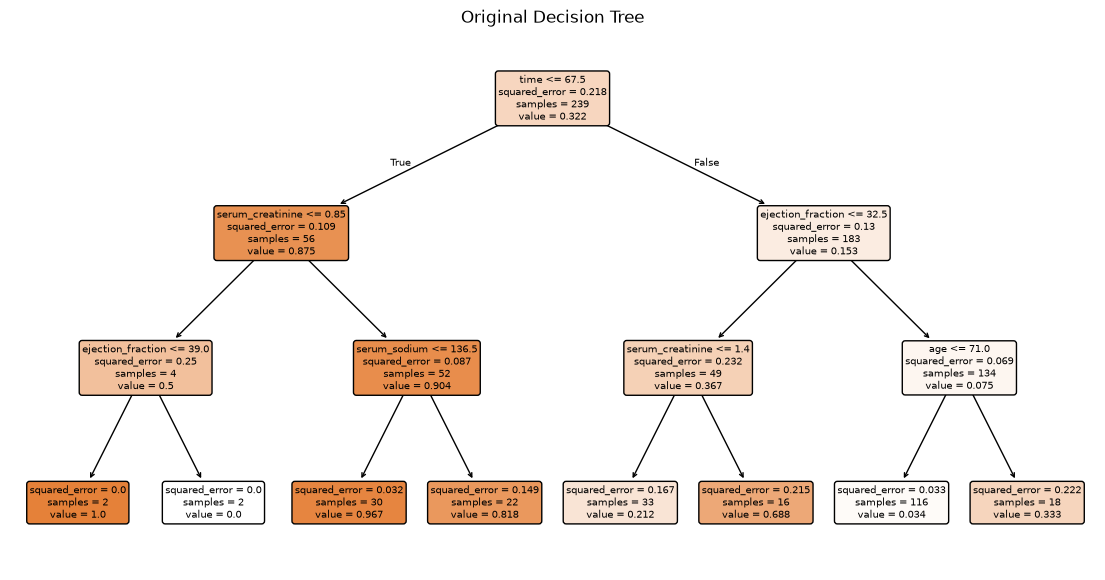

In [2]:
# Question 2

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

X = df.drop(columns=["DEATH_EVENT"])
y = df["DEATH_EVENT"]

seed = 10

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=seed, stratify=y
)

tree = DecisionTreeRegressor(max_depth=3, random_state=seed)
linear = LinearRegression()

tree.fit(X_train, y_train)
linear.fit(X_train, y_train)

tree_pred = tree.predict(X_test)
linear_pred = linear.predict(X_test)

print("Decision Tree:")
print("MSE:", mean_squared_error(y_test, tree_pred))
print("R2:", r2_score(y_test, tree_pred))

print("\nLinear Regression:")
print("MSE:", mean_squared_error(y_test, linear_pred))
print("R2:", r2_score(y_test, linear_pred))

print("\nLinear coefficients:")
print(pd.Series(linear.coef_, index=X.columns))

plt.figure(figsize=(14, 7))
plot_tree(tree, feature_names=X.columns, filled=True, rounded=True)
plt.title("Original Decision Tree")
plt.show()

After using an 80/20 train-test split with random seed 10, the decision tree had a test MSE of 0.1292 and R² of 0.4029, while linear regression had a test MSE of 0.1330 and R² of 0.3855. The decision tree performed slightly better because it had a lower MSE and higher R².

Additionally, we limited the trees to depth 3 because the dataset is small (299 patients, ~239 in training). A shallow tree is interpretable and avoids memorizing noise in the training set. A fully grown tree would fit each training split almost perfectly and look wildly different from seed to seed, so it would exaggerate the instability. Depth 3 is, therefore, a favorable setting since if they are still less stable than linear regression here, deeper trees would likely be at least as unstable.

Seed: 30
Tree R2: 0.3564
Linear R2: 0.3785
Tree root feature: time

Seed: 50
Tree R2: 0.3517
Linear R2: 0.3651
Tree root feature: time

Seed: 70
Tree R2: 0.4396
Linear R2: 0.3552
Tree root feature: time

Seed: 90
Tree R2: 0.3175
Linear R2: 0.3434
Tree root feature: time

Linear coefficients across seeds:
                              30      50      70      90
age                       0.0056  0.0057  0.0071  0.0070
anaemia                   0.0362  0.0394  0.0057 -0.0194
creatinine_phosphokinase  0.0000  0.0000  0.0000  0.0000
diabetes                  0.0242  0.0032 -0.0244  0.0040
ejection_fraction        -0.0101 -0.0118 -0.0110 -0.0111
high_blood_pressure       0.0012 -0.0374 -0.0273 -0.0606
platelets                -0.0000  0.0000  0.0000  0.0000
serum_creatinine          0.0628  0.0549  0.0462  0.0322
serum_sodium             -0.0083 -0.0080 -0.0026 -0.0085
sex                      -0.1229 -0.1278 -0.0682 -0.0334
smoking                   0.0592  0.0829 -0.0253  0.0004
time      

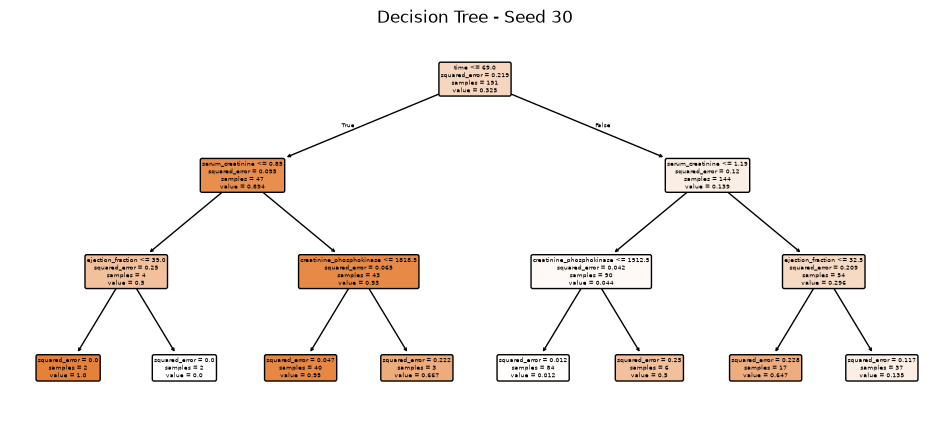

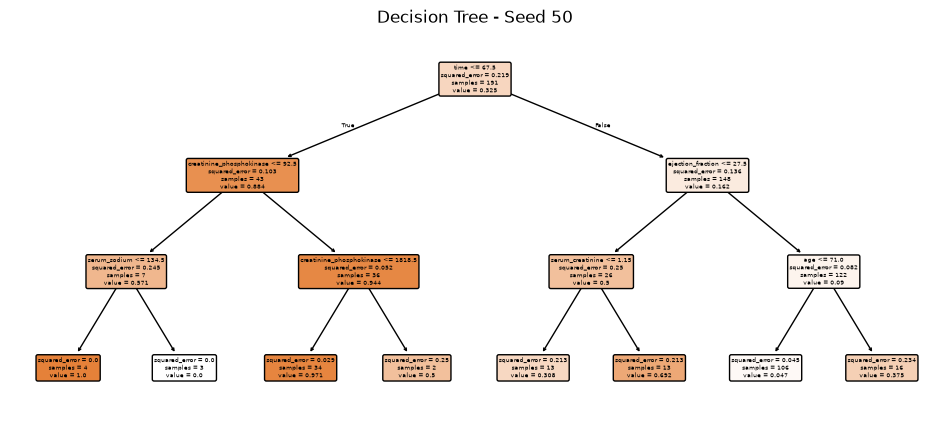

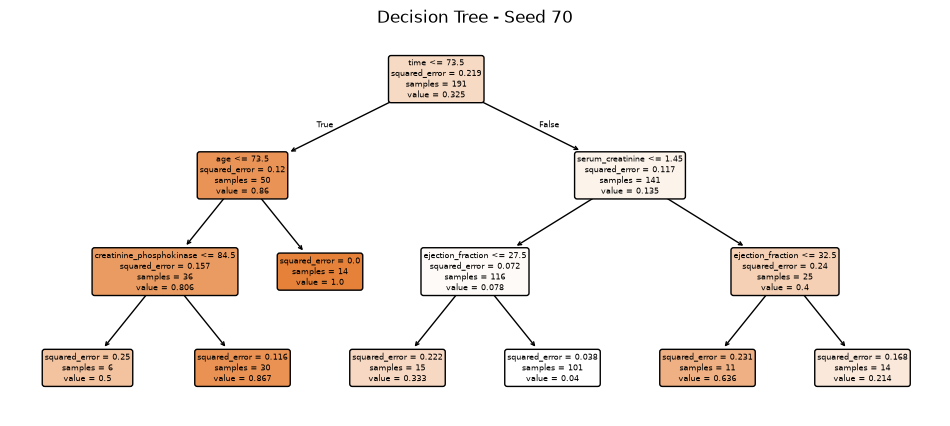

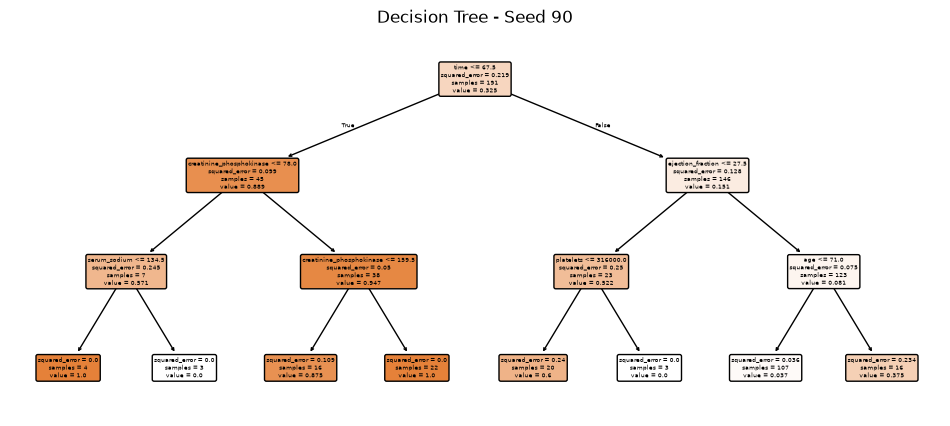

===== Tree, seed 10 =====
|--- time <= 67.5
|   |--- serum_creatinine <= 0.8
|   |   |--- ejection_fraction <= 39.0
|   |   |   |--- value: [1.0]
|   |   |--- ejection_fraction >  39.0
|   |   |   |--- value: [0.0]
|   |--- serum_creatinine >  0.8
|   |   |--- serum_sodium <= 136.5
|   |   |   |--- value: [1.0]
|   |   |--- serum_sodium >  136.5
|   |   |   |--- value: [0.8]
|--- time >  67.5
|   |--- ejection_fraction <= 32.5
|   |   |--- serum_creatinine <= 1.4
|   |   |   |--- value: [0.2]
|   |   |--- serum_creatinine >  1.4
|   |   |   |--- value: [0.7]
|   |--- ejection_fraction >  32.5
|   |   |--- age <= 71.0
|   |   |   |--- value: [0.0]
|   |   |--- age >  71.0
|   |   |   |--- value: [0.3]

===== Tree, seed 30 =====
|--- time <= 69.0
|   |--- serum_creatinine <= 0.8
|   |   |--- ejection_fraction <= 39.0
|   |   |   |--- value: [1.0]
|   |   |--- ejection_fraction >  39.0
|   |   |   |--- value: [0.0]
|   |--- serum_creatinine >  0.8
|   |   |--- creatinine_phosphokinase <= 

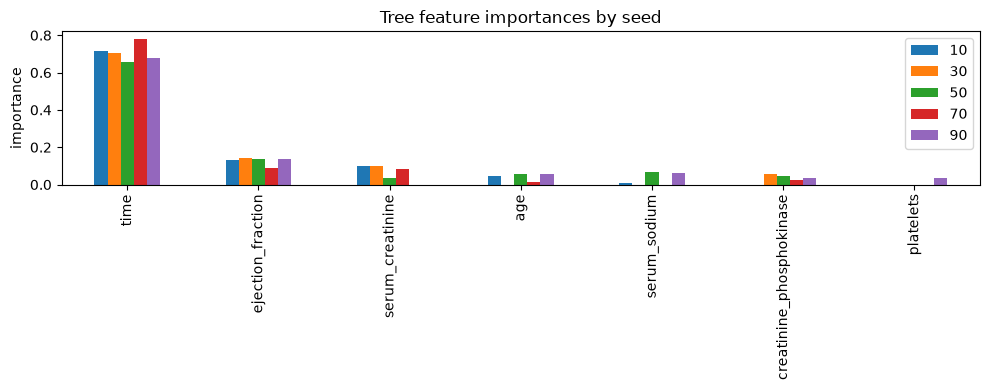


Linear coefficients, seed 10 included:
                              10      30      50      70      90
age                       0.0060  0.0056  0.0057  0.0071  0.0070
anaemia                   0.0099  0.0362  0.0394  0.0057 -0.0194
creatinine_phosphokinase  0.0000  0.0000  0.0000  0.0000  0.0000
diabetes                  0.0089  0.0242  0.0032 -0.0244  0.0040
ejection_fraction        -0.0097 -0.0101 -0.0118 -0.0110 -0.0111
high_blood_pressure      -0.0263  0.0012 -0.0374 -0.0273 -0.0606
platelets                 0.0000 -0.0000  0.0000  0.0000  0.0000
serum_creatinine          0.0583  0.0628  0.0549  0.0462  0.0322
serum_sodium             -0.0097 -0.0083 -0.0080 -0.0026 -0.0085
sex                      -0.0734 -0.1229 -0.1278 -0.0682 -0.0334
smoking                   0.0153  0.0592  0.0829 -0.0253  0.0004
time                     -0.0029 -0.0030 -0.0028 -0.0029 -0.0030


In [5]:
# Question 3
from sklearn.tree import export_text

seeds = [30, 50, 70, 90]

tree_predictions = {}
linear_predictions = {}
tree_models = {}
linear_coefficients = {}

for s in seeds:
    X_sub, _, y_sub, _ = train_test_split(
        X_train, y_train,
        train_size=0.8,
        random_state=s,
        stratify=y_train
    )

    t = DecisionTreeRegressor(max_depth=3, random_state=s)
    l = LinearRegression()

    t.fit(X_sub, y_sub)
    l.fit(X_sub, y_sub)

    tree_models[s] = t
    tree_predictions[s] = t.predict(X_test)
    linear_predictions[s] = l.predict(X_test)
    linear_coefficients[s] = l.coef_

    print("Seed:", s)
    print("Tree R2:", round(r2_score(y_test, tree_predictions[s]), 4))
    print("Linear R2:", round(r2_score(y_test, linear_predictions[s]), 4))
    print("Tree root feature:", X.columns[t.tree_.feature[0]])
    print()

coef_table = pd.DataFrame(
    linear_coefficients,
    index=X.columns
)

print("Linear coefficients across seeds:")
print(coef_table.round(4))

for s in seeds:
    plt.figure(figsize=(12, 5))
    plot_tree(
        tree_models[s],
        feature_names=X.columns,
        filled=True,
        rounded=True
    )
    plt.title("Decision Tree - Seed " + str(s))
    plt.show()

# added code
all_trees = {10: tree, **tree_models}          # seed 10 is the reference tree
feature_names = list(X.columns)

for s, t in all_trees.items():
    print(f"===== Tree, seed {s} =====")
    print(export_text(t, feature_names=feature_names, decimals=1))

def split_table(t, s):
    tr = t.tree_
    out, stack = [], [(0, 0)]
    while stack:
        node, depth = stack.pop()
        if tr.children_left[node] != -1:
            out.append({"seed": s, "depth": depth, "feature": feature_names[tr.feature[node]],
                        "threshold": round(tr.threshold[node], 2)})
            stack += [(tr.children_right[node], depth + 1), (tr.children_left[node], depth + 1)]
    return pd.DataFrame(out).sort_values(["depth", "feature", "threshold"])

splits = pd.concat([split_table(t, s) for s, t in all_trees.items()], ignore_index=True)
print("Splits by depth:")
print(splits.to_string(index=False))

print("\nRoot split and depth-1 splits:")
print(splits[splits["depth"] <= 1].to_string(index=False))

importances = pd.DataFrame({s: t.feature_importances_ for s, t in all_trees.items()},
                           index=feature_names)
print("\nFeature importances:")
print(importances.round(3))
importances.loc[importances.max(axis=1) > 0].sort_values(10, ascending=False).plot.bar(figsize=(10, 4))
plt.title("Tree feature importances by seed")
plt.ylabel("importance")
plt.tight_layout()
plt.show()

# linear coeff with seed 10 model included as the reference column
coef_table_full = coef_table.copy()
coef_table_full.insert(0, 10, linear.coef_)
print("\nLinear coefficients, seed 10 included:")
print(coef_table_full.round(4))

The models were repeated using seeds 30, 50, 70, and 90. All four trees initially split on time, but their later splits, variables, and thresholds differed noticeably. The linear regression coefficients were generally more consistent, although some changed in size or sign. Tree R² ranged from 0.3175 to 0.4396, while linear regression R² ranged from 0.3434 to 0.3785. This suggests that decision trees are more sensitive to changes in the training data than linear regression.

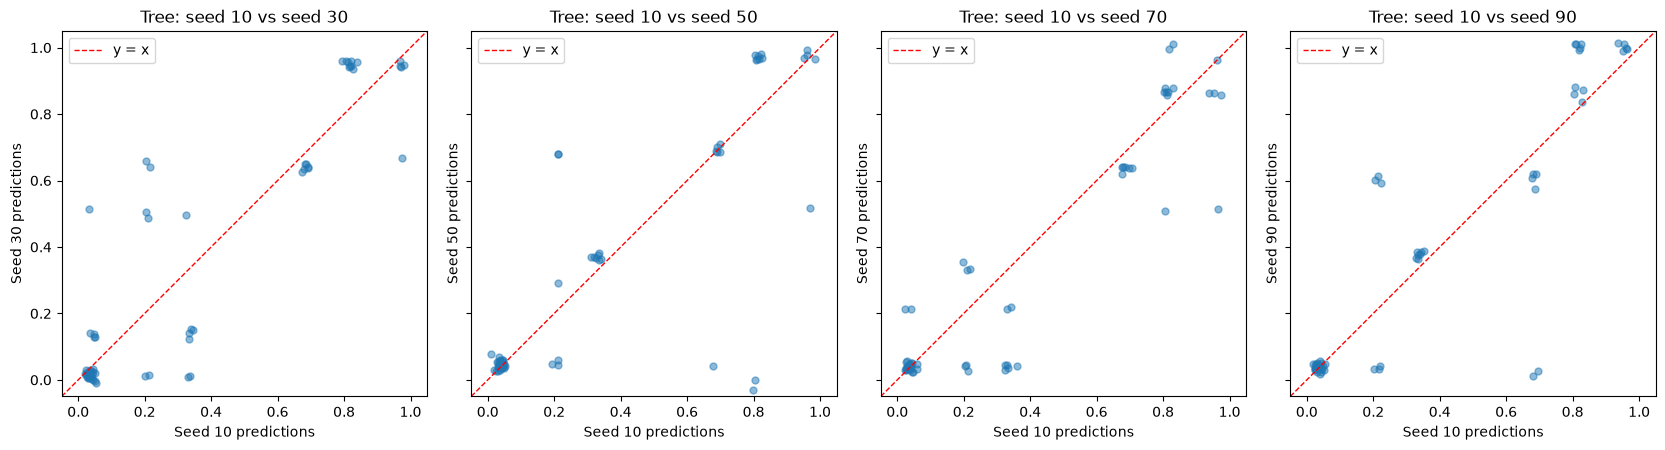

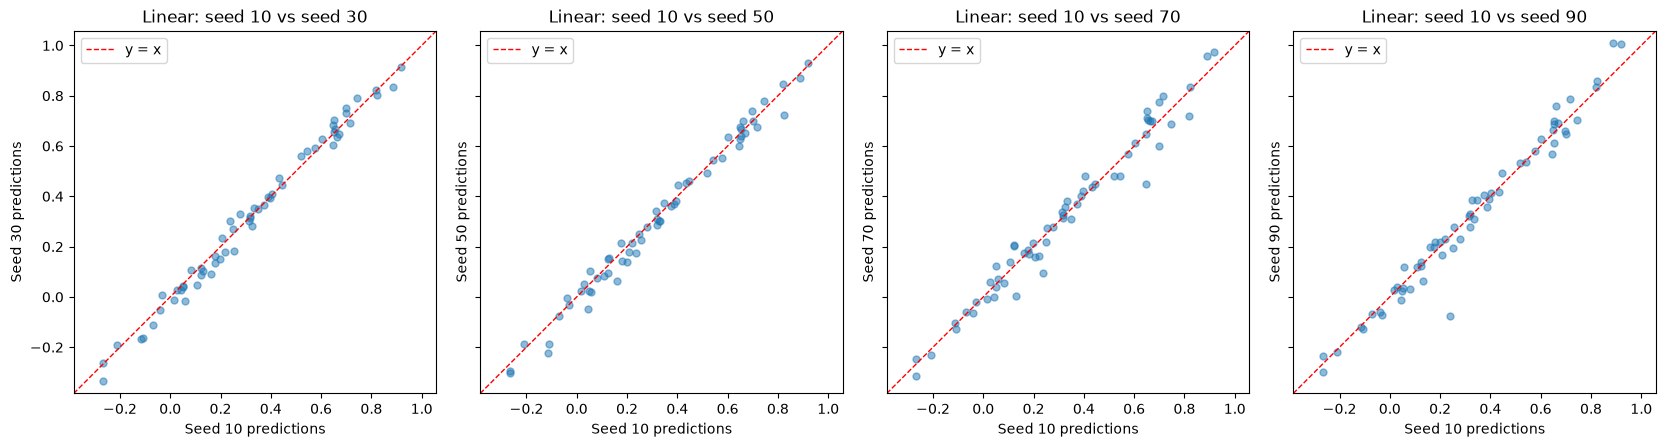

Number of distinct predicted values on the test set (seed 10): tree = 6 , linear = 60
Tree correlations:
30 0.9099
50 0.828
70 0.9299
90 0.9023

Linear correlations:
30 0.9943
50 0.993
70 0.9836
90 0.9846

Tree regressions (slope, intercept, R2):
30 1.0012 0.0117 0.828
50 0.8742 0.0369 0.6856
70 0.9311 -0.0107 0.8648
90 0.9931 0.0128 0.8141

Linear regressions (slope, intercept, R2):
30 1.0373 -0.0183 0.9887
50 1.0229 -0.0182 0.9861
70 1.0143 -0.0048 0.9676
90 1.0454 -0.0159 0.9695


In [6]:
# Question 4
import matplotlib.pyplot as plt

#a.(trees and linear models respectively)
def pred_scatter(base_pred, alt_preds, model_name, jitter=0.0):
    rng = np.random.default_rng(0)
    fig, axes = plt.subplots(1, len(seeds), figsize=(4.2 * len(seeds), 4.2), sharex=True, sharey=True)
    lo = min(base_pred.min(), *(p.min() for p in alt_preds.values())) - 0.05
    hi = max(base_pred.max(), *(p.max() for p in alt_preds.values())) + 0.05
    for ax, s in zip(axes, seeds):
        x = base_pred + rng.normal(0, jitter, len(base_pred))   # jitter only for display
        y = alt_preds[s] + rng.normal(0, jitter, len(base_pred))
        ax.scatter(x, y, alpha=0.5, s=25)
        ax.plot([lo, hi], [lo, hi], "r--", lw=1, label="y = x")
        ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
        ax.set_title(f"{model_name}: seed 10 vs seed {s}")
        ax.set_xlabel("Seed 10 predictions"); ax.set_ylabel(f"Seed {s} predictions")
        ax.legend(loc="upper left")
    plt.tight_layout()
    plt.show()

# Trees predict only a handful of distinct values, so points overlap: add a little jitter.
pred_scatter(tree_pred, tree_predictions, "Tree", jitter=0.01)
pred_scatter(linear_pred, linear_predictions, "Linear", jitter=0.0)
print("Number of distinct predicted values on the test set (seed 10):",
      "tree =", len(np.unique(tree_pred)), ", linear =", len(np.unique(linear_pred)))

#b. (Trees followed by linear models)
print("Tree correlations:")
for s in seeds:
    print(s, round(np.corrcoef(tree_pred, tree_predictions[s])[0, 1], 4))

print("\nLinear correlations:")
for s in seeds:
    print(s, round(np.corrcoef(linear_pred, linear_predictions[s])[0, 1], 4))  

#c. (Trees followed by linear models)
print("\nTree regressions (slope, intercept, R2):")
for s in seeds:
    slope, intercept = np.polyfit(tree_pred, tree_predictions[s], 1)
    r2 = np.corrcoef(tree_pred, tree_predictions[s])[0, 1] ** 2
    print(s, round(slope, 4), round(intercept, 4), round(r2, 4))

print("\nLinear regressions (slope, intercept, R2):")
for s in seeds:
    slope, intercept = np.polyfit(linear_pred, linear_predictions[s], 1)
    r2 = np.corrcoef(linear_pred, linear_predictions[s])[0, 1] ** 2
    print(s, round(slope, 4), round(intercept, 4), round(r2, 4))

The linear model predictions are quite similar across seeds, as the points are situated closely to the straight diagonal line. However, the points of the tree predictions lie further from the diagonal line. While the linear model predictions are very similar, the tree predictions are significantly less similar and are more scattered. Both the linear models and the trees are highly correlated with the seed 10 model ranging from (0.984 to 0.994) and the trees model (0.828 to 0.930). When comparing the correlations between the seed and linear models, the linear model is more highly correlated. In the linear models, the intercepts are close to 0 (-0.018 to -0.005), while the slopes are close to 1 (1.0143 to 1.0454), and the r(sq) is also close to 1 (0.9676 - 0.9887). In the trees the intercepts are again close to 0 (-0.0107 - 0.0369) and most of the slopes are close to 1 ranging from 0.8742 to 1.0012. Lastly, the R squared values are lower with the values ranging from 0.6856 to 0.8648. This also shows that seed 50 is the weakest due to its lower R squared value. Overall, the linear models are more stable compared to the trees.

In [7]:
# Question 5:
print("Linear coefficients across seeds:")
print(coef_table.round(4))

for s in seeds:
    print("Seed", s)
    print("  Tree root feature:", X.columns[tree_models[s].tree_.feature[0]])
    print("  Tree test R2:", round(r2_score(y_test, tree_predictions[s]), 4))
    print("  Linear test R2:", round(r2_score(y_test, linear_predictions[s]), 4))

Linear coefficients across seeds:
                              30      50      70      90
age                       0.0056  0.0057  0.0071  0.0070
anaemia                   0.0362  0.0394  0.0057 -0.0194
creatinine_phosphokinase  0.0000  0.0000  0.0000  0.0000
diabetes                  0.0242  0.0032 -0.0244  0.0040
ejection_fraction        -0.0101 -0.0118 -0.0110 -0.0111
high_blood_pressure       0.0012 -0.0374 -0.0273 -0.0606
platelets                -0.0000  0.0000  0.0000  0.0000
serum_creatinine          0.0628  0.0549  0.0462  0.0322
serum_sodium             -0.0083 -0.0080 -0.0026 -0.0085
sex                      -0.1229 -0.1278 -0.0682 -0.0334
smoking                   0.0592  0.0829 -0.0253  0.0004
time                     -0.0030 -0.0028 -0.0029 -0.0030
Seed 30
  Tree root feature: time
  Tree test R2: 0.3564
  Linear test R2: 0.3785
Seed 50
  Tree root feature: time
  Tree test R2: 0.3517
  Linear test R2: 0.3651
Seed 70
  Tree root feature: time
  Tree test R2: 0.4396
  Li

This code summarizes how stable the models were across the four seeds from question 3. The linear models have similar coefficients for certain (most) variables and are even consistent across seeds. The most stable variables include the time variable which has very similar coefficients across seeds (about -0.003), ejection fraction (around -0.011), and age. The serum_sodium and serum_creatinine are moderately stable where the coefficients are always positive (0.0628 to 0.0322) and always negative (-0.0083 to -0.0026), respectively. The unstable variables are as follows: sex changes by about a factor of four (-0.1229 to -0.0334). anaemia (0.0394 to -0.0194), diabetes (0.0242 to -0.0244) and smoking (0.0829 to -0.0253) change sign. high_blood_pressure ranges from 0.0012 to -0.0606.

This presents that the linear models are fairly consistent since predictions are consistent despite differences in coefficients. Their correlation with the seed 10 predictions is between 0.984 and 0.994, and the test R² only ranges from 0.343 to 0.379. However, the trees are less stable although they always split first on time, but the splits that come after are different from seed to seed. The predictions also vary more than the linear ones. Their correlation with the seed 10 tree is 0.828 to 0.930, and the regression R² of the alternative predictions on the seed 10 predictions ranges from 0.686 to 0.865. Test R² ranges from 0.318 to 0.440, a spread of about 0.12 compared with about 0.04 for linear regression. This means that the structure is unstable. In summary, linear models are fairly stable with similar coefficients for key variables and very similar predictions across splits, while trees are less stable, with consistent first split on time but different splits below it and less consistent predictions.

*Also note that we fit models as regressions on DEATH_EVENT so that each produces a numeric prediction on the same scale, which can be read as an estimated probability of death. For the tree, each leaf predicts the fraction of deaths among the training patients in it. Class labels would reduce every prediction to 0 or 1 and hide the differences we want to measure. The trade-offs, however, are that linear predictions can fall outside [0, 1], and that a depth-3 tree can output at most 8 distinct values, which is why scatterplots made in Q4 use jitter. The check at the end of Q5 counts how many predictions fall outside [0, 1].

Question 6:

True. Even if the models end up having a substantially different appearance, the predictions are often similar. Even though the trees' structures and the linear models' coefficients change from seed to seed, the predictions on the same test set remain similar. This trend is more significant in the linear models (correlation ≥ 0.98), but still holds true for the trees' (lower correlations of 0.83-0.93). For this data set, the trees use different splits below the first split, which is time, and the linear models have varying coefficients for certain variables, so the models look noticeably different from seed to seed. Specifically, test R² for trees also swings more across seeds (range about 0.12) than for linear (about 0.04). However, the predictions on the same test set are very similar because many variable carry overlapping information, so different models can reach the same predictions using different methods. Trees are somewhat less consistent than the linear models.

### *Reflection on AI assistance
In your own words without generative AI.

Of the AI’s ten proposed changes, we accepted six, modified two, and rejected two. The most useful improvements came from the AI checking our written answers against our actual output. It found that the Q3 R^2 ranges were left over from an earlier run, and that Q5 overstated how stable the linear coefficients were across seeds. In response, we double-checked the tree outputs and added quantitative evidence for Q5 and Q6. We printed each tree’s full structure and added reference lines to the Q4 scatterplots. We also justified our choice of max_depth=3, explained why we used regression models on a binary outcome, and made our Q1 cleaning more thorough.

The AI’s main limitation was that some suggestions went beyond what the questions asked. For example, it recommended hedging our Q2 conclusion using the Q3 results, but Q2 asks about a single split, and our conclusion holds for that split. We also rejected its suggestion to standardize features because it was not needed to answer Q5. For Q6, much of its feedback repeated points our answer already made, so we kept our response but added numbers to support it. The AI was a useful reviewer, but we still had to decide which suggestions fit the assignment’s scope.

To verify the final solution, we reran the entire notebook and checked the numbers in our written answers against the printed output. We also double-checked our full tree structure instead of relying only on the root feature and made sure that each change appeared in the plots. Some concerns do remain. The Q2 model ranking reflects only one split, and linear predictions can fall outside the 0-1 range. Also, because the dataset is small, results may shift with different random seeds.